In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Metro_Interstate_Traffic_Volume.csv")

df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [3]:
df.shape

(48204, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 5.0 MB


In [5]:
df.describe()

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,281.205870,0.334264,0.000222,49.362231,3259.818355
std,13.338232,44.789133,0.008168,39.015750,1986.860670
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,7280.000000


In [6]:
print(df.isnull().sum())

holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64


In [7]:
print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after cleaning:", df.duplicated().sum())

Duplicates before cleaning: 17
Duplicates after cleaning: 0


In [8]:
df["date_time"] = pd.to_datetime(
    df["date_time"],
    errors="coerce"
)

print(df["date_time"].head())

0   2012-10-02 09:00:00
1   2012-10-02 10:00:00
2   2012-10-02 11:00:00
3   2012-10-02 12:00:00
4   2012-10-02 13:00:00
Name: date_time, dtype: datetime64[us]


In [9]:
df["holiday"] = df["holiday"].fillna("None")

print("Missing holiday values:", df["holiday"].isnull().sum())

Missing holiday values: 0


In [10]:
df = df.dropna(subset=["date_time"])

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (48187, 9)


In [11]:
df["year"] = df["date_time"].dt.year

df["month"] = df["date_time"].dt.month

df["day"] = df["date_time"].dt.day

df["hour"] = df["date_time"].dt.hour

df["day_of_week"] = df["date_time"].dt.dayofweek

df["is_weekend"] = df["day_of_week"].apply(
    lambda x: 1 if x >= 5 else 0
)

df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,year,month,day,hour,day_of_week,is_weekend
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,2012,10,2,9,1,0
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,2012,10,2,10,1,0
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,2012,10,2,11,1,0
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,2012,10,2,12,1,0
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,2012,10,2,13,1,0


In [12]:
print(df[["date_time","year","month", "day","hour","day_of_week","is_weekend"]].head())

            date_time  year  month  day  hour  day_of_week  is_weekend
0 2012-10-02 09:00:00  2012     10    2     9            1           0
1 2012-10-02 10:00:00  2012     10    2    10            1           0
2 2012-10-02 11:00:00  2012     10    2    11            1           0
3 2012-10-02 12:00:00  2012     10    2    12            1           0
4 2012-10-02 13:00:00  2012     10    2    13            1           0


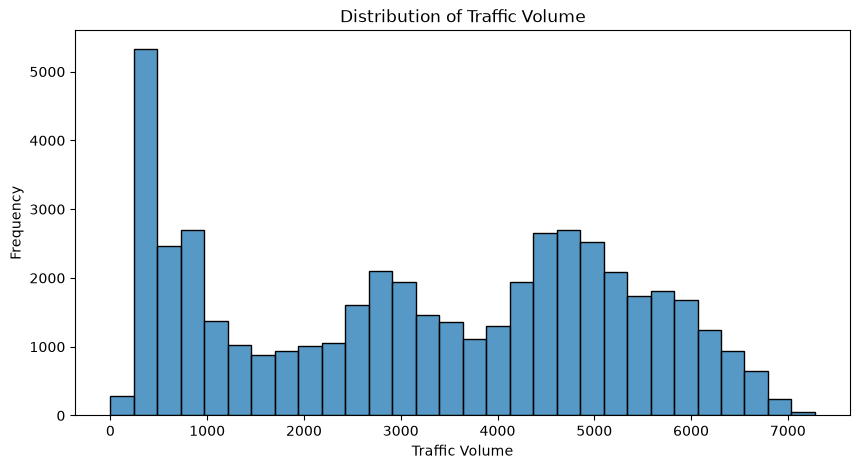

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

sns.histplot(df["traffic_volume"], bins=30)

plt.title("Distribution of Traffic Volume")
plt.xlabel("Traffic Volume")
plt.ylabel("Frequency")

plt.show()

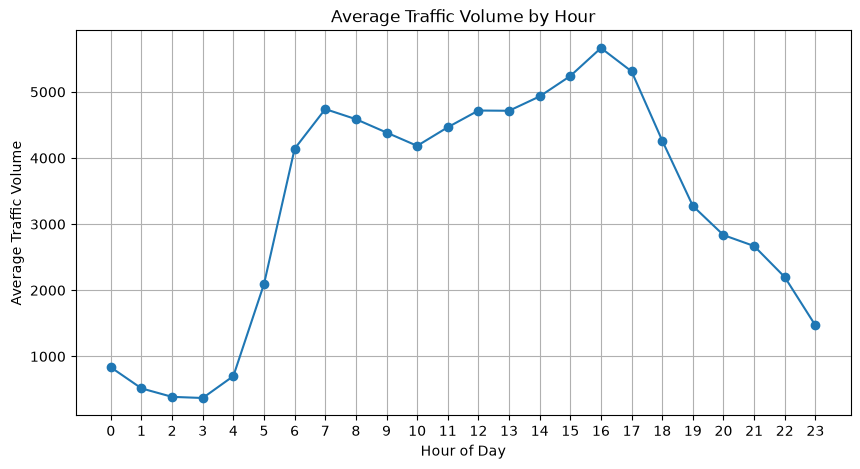

In [14]:
hourly_traffic = df.groupby("hour")["traffic_volume"].mean()

plt.figure(figsize=(10, 5))

hourly_traffic.plot(kind="line", marker="o")

plt.title("Average Traffic Volume by Hour")

plt.xlabel("Hour of Day")

plt.ylabel("Average Traffic Volume")

plt.xticks(range(24))

plt.grid(True)

plt.show()

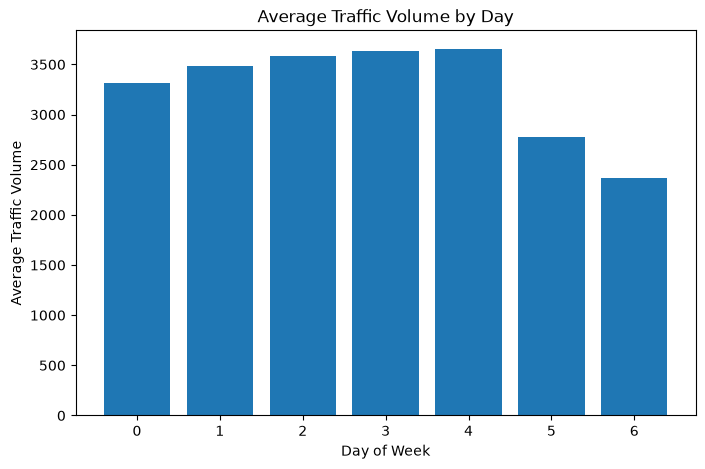

In [15]:
daily_traffic = df.groupby("day_of_week")["traffic_volume"].mean()

plt.figure(figsize=(8,5))

plt.bar(daily_traffic.index, daily_traffic.values)

plt.title("Average Traffic Volume by Day")
plt.xlabel("Day of Week")
plt.ylabel("Average Traffic Volume")

plt.show()

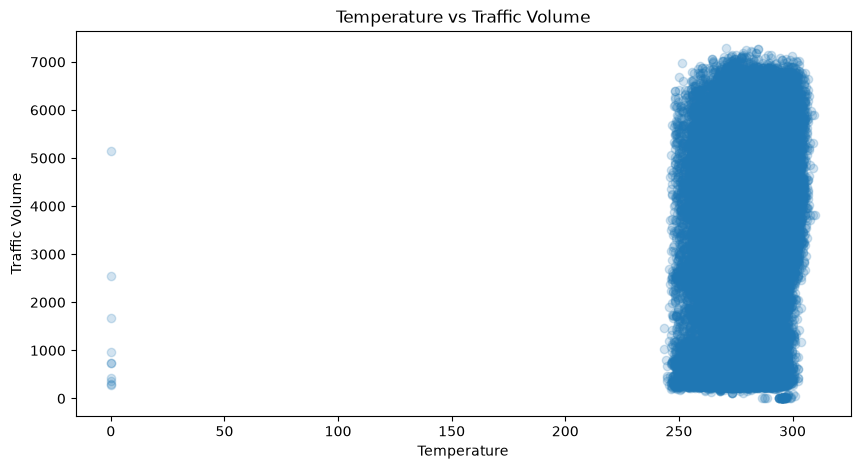

In [16]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["temp"],
    df["traffic_volume"],
    alpha=0.2
)

plt.title("Temperature vs Traffic Volume")

plt.xlabel("Temperature")

plt.ylabel("Traffic Volume")

plt.show()

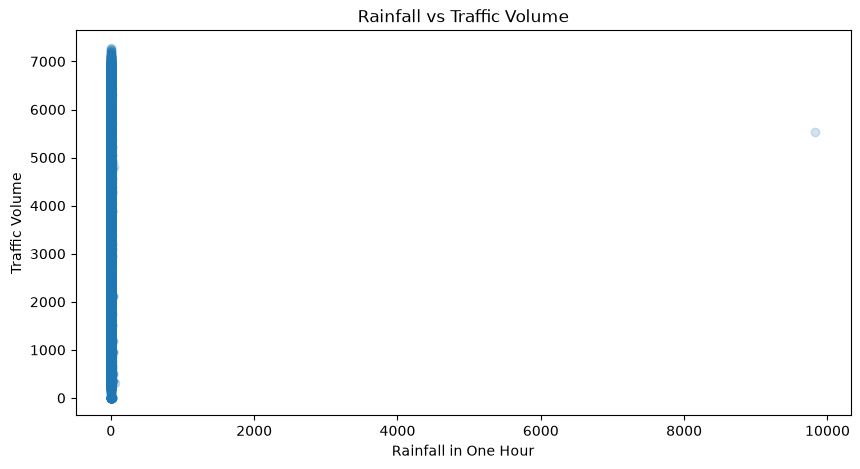

In [17]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df["rain_1h"],
    df["traffic_volume"],
    alpha=0.2
)

plt.title("Rainfall vs Traffic Volume")

plt.xlabel("Rainfall in One Hour")

plt.ylabel("Traffic Volume")

plt.show()

In [18]:
y = df["traffic_volume"]

In [19]:
# Remove the original datetime column
df_model = df.drop("date_time", axis=1)

# Separate features and target
X = df_model.drop("traffic_volume", axis=1)

y = df_model["traffic_volume"]

print("Features shape before encoding:", X.shape)

print("Target shape:", y.shape)

Features shape before encoding: (48187, 13)
Target shape: (48187,)


In [20]:
X = pd.get_dummies(
    X,
    columns=[
        "holiday",
        "weather_main",
        "weather_description"
    ],
    dtype=int
)

print("Features shape after encoding:", X.shape)

print("Target shape:", y.shape)

Features shape after encoding: (48187, 71)
Target shape: (48187,)


In [21]:
X.head()

,temp,rain_1h,snow_1h,clouds_all,year,month,day,hour,day_of_week,is_weekend,...,weather_description_sleet,weather_description_smoke,weather_description_snow,weather_description_thunderstorm,weather_description_thunderstorm with drizzle,weather_description_thunderstorm with heavy rain,weather_description_thunderstorm with light drizzle,weather_description_thunderstorm with light rain,weather_description_thunderstorm with rain,weather_description_very heavy rain
0,288.28,0.0,0.0,40,2012,10,2,9,1,0,...,0,0,0,0,0,0,0,0,0,0
1,289.36,0.0,0.0,75,2012,10,2,10,1,0,...,0,0,0,0,0,0,0,0,0,0
2,289.58,0.0,0.0,90,2012,10,2,11,1,0,...,0,0,0,0,0,0,0,0,0,0
3,290.13,0.0,0.0,90,2012,10,2,12,1,0,...,0,0,0,0,0,0,0,0,0,0
4,291.14,0.0,0.0,75,2012,10,2,13,1,0,...,0,0,0,0,0,0,0,0,0,0


In [48]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Check the data sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (38549, 71)
Testing data: (9638, 71)


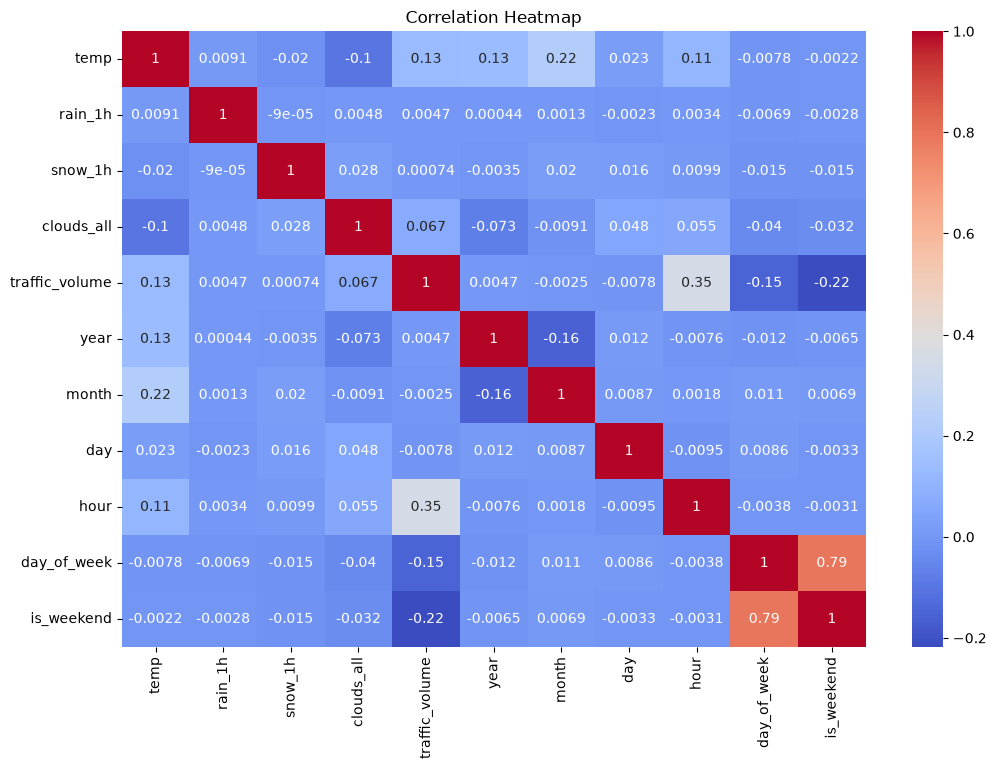

In [23]:
correlation = df.corr(numeric_only=True)
plt.figure(figsize=(12,8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

In [24]:
from sklearn.linear_model import LinearRegression
model_lr = LinearRegression()
model_lr.fit( X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

In [25]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

r2_lr = r2_score(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test,y_pred_lr ))

print("Linear Regression")
print("R2 Score:", r2_lr)
print("MAE:", mae_lr)
print("RMSE:", rmse_lr)

Linear Regression
R2 Score: 0.19706030008705233
MAE: 1539.3400764251157
RMSE: 1763.1045738631817


In [26]:

from sklearn.tree import DecisionTreeRegressor
model_dt = DecisionTreeRegressor(random_state=42)
model_dt.fit( X_train,y_train)
y_pred_dt = model_dt.predict(X_test)

In [27]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

r2_dt = r2_score(y_test, y_pred_dt)
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error( y_test,y_pred_dt ))

print("Decision Tree")
print("R2 Score:", r2_dt)
print("MAE:", mae_dt)
print("RMSE:", rmse_dt)

Decision Tree
R2 Score: 0.8907330143638134
MAE: 371.55965968043165
RMSE: 650.4008311255951


In [28]:
from sklearn.ensemble import RandomForestRegressor
model_rf = RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)
model_rf.fit( X_train,y_train)
y_pred_rf = model_rf.predict(X_test)

In [29]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

r2_rf = r2_score(y_test, y_pred_rf)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error( y_test,y_pred_rf))

print("Random Forest")
print("R2 Score:", r2_rf)
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)

Random Forest
R2 Score: 0.9375860593270842
MAE: 283.4293432247354
RMSE: 491.5609878378377


In [30]:
!pip install xgboost
from xgboost import XGBRegressor
model_xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

model_xgb.fit(X_train, y_train)
y_pred_xgb = model_xgb.predict(X_test)

In [31]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

r2_xgb = r2_score(y_test, y_pred_xgb)

mae_xgb = mean_absolute_error(
    y_test,
    y_pred_xgb
)

rmse_xgb = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_xgb
    )
)

print("XGBoost Results")
print("----------------")
print("R² Score:", r2_xgb)
print("MAE:", mae_xgb)
print("RMSE:", rmse_xgb)

XGBoost Results
----------------
R² Score: 0.934459924697876
MAE: 297.7846984863281
RMSE: 503.7210134340238


In [34]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],

    "R2 Score": [
        r2_lr,
        r2_dt,
        r2_rf,
        r2_xgb
    ],

    "MAE": [
        mae_lr,
        mae_dt,
        mae_rf,
        mae_xgb
    ],

    "RMSE": [
        rmse_lr,
        rmse_dt,
        rmse_rf,
        rmse_xgb
    ]
})

results = results.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

results

,Model,R2 Score,MAE,RMSE
0,Random Forest,0.937586,283.429343,491.560988
1,XGBoost,0.934460,297.784698,503.721013
2,Decision Tree,0.890733,371.559660,650.400831
3,Linear Regression,0.197060,1539.340076,1763.104574


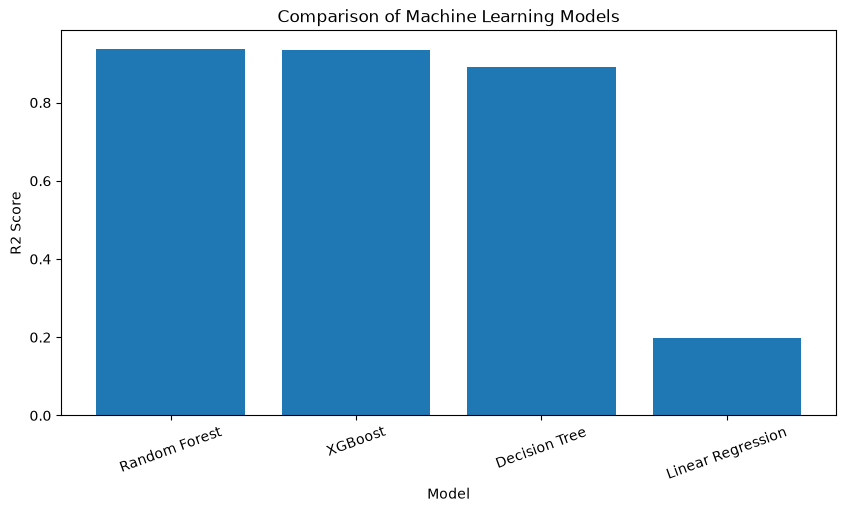

In [35]:
plt.figure(figsize=(10, 5))

plt.bar(
    results["Model"],
    results["R2 Score"]
)

plt.title("Comparison of Machine Learning Models")

plt.xlabel("Model")

plt.ylabel("R2 Score")

plt.xticks(rotation=20)

plt.show()

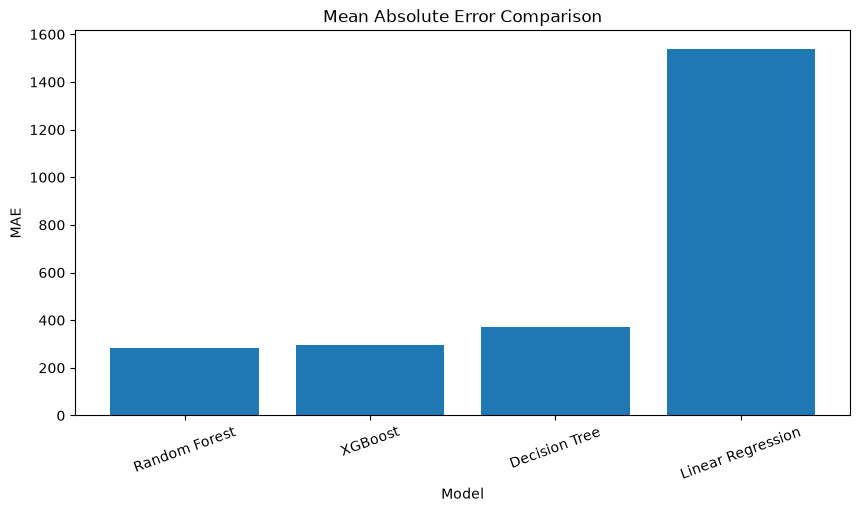

In [36]:
plt.figure(figsize=(10, 5))

plt.bar(
    results["Model"],
    results["MAE"]
)

plt.title("Mean Absolute Error Comparison")

plt.xlabel("Model")

plt.ylabel("MAE")

plt.xticks(rotation=20)

plt.show()

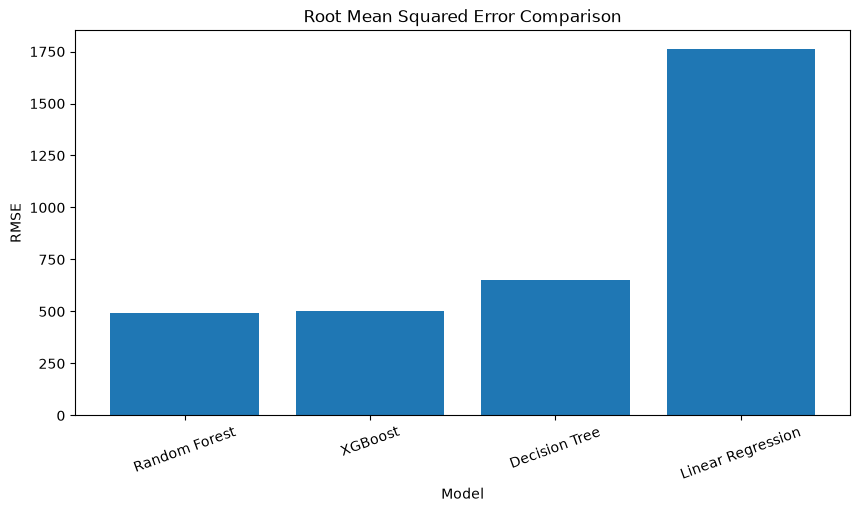

In [37]:
plt.figure(figsize=(10, 5))

plt.bar(
    results["Model"],
    results["RMSE"]
)

plt.title("Root Mean Squared Error Comparison")

plt.xlabel("Model")

plt.ylabel("RMSE")

plt.xticks(rotation=20)

plt.show()

In [38]:
trained_models = {
    "Linear Regression": model_lr,
    "Decision Tree": model_dt,
    "Random Forest": model_rf,
    "XGBoost": model_xgb
}

best_model_name = results.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

print("Best R2 Score:", results.iloc[0]["R2 Score"])

print("Best MAE:", results.iloc[0]["MAE"])

print("Best RMSE:", results.iloc[0]["RMSE"])

Best Model: Random Forest
Best R2 Score: 0.9375860593270842
Best MAE: 283.4293432247354
Best RMSE: 491.5609878378377


In [39]:
y_pred_best = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Traffic": y_test.values,
    "Predicted Traffic": y_pred_best
})

comparison.head(10)

,Actual Traffic,Predicted Traffic
0,2704,2486.27
1,2704,2483.71
2,2704,2561.23
3,2204,2292.19
4,2204,2393.38
5,1713,1899.62
6,1713,1910.61
7,1068,1106.73
8,611,629.70
9,362,387.28


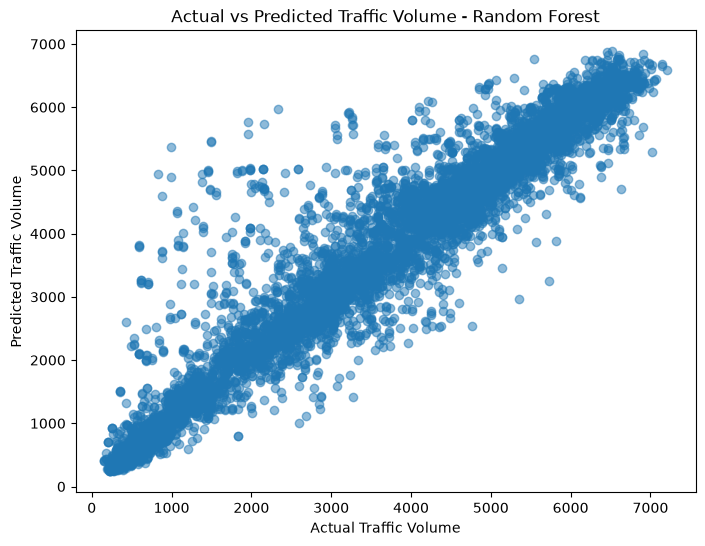

In [40]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_rf,alpha=0.5)
plt.xlabel("Actual Traffic Volume")
plt.ylabel("Predicted Traffic Volume")

plt.title("Actual vs Predicted Traffic Volume - Random Forest")

plt.show()

In [41]:
feature_importance = pd.DataFrame({"Feature": X.columns, "Importance": model_rf.feature_importances_})
feature_importance = feature_importance.sort_values( by="Importance",ascending=False)
feature_importance

,Feature,Importance
7,hour,8.288823e-01
8,day_of_week,6.288159e-02
9,is_weekend,4.615617e-02
0,temp,1.701889e-02
6,day,1.621607e-02
...,...,...
62,weather_description_smoke,8.519436e-08
67,weather_description_thunderstorm with light dr...,6.246448e-08
47,weather_description_light rain and snow,2.655756e-08
14,holiday_Martin Luther King Jr Day,7.871176e-09


In [42]:
feature_importance.head(10)

,Feature,Importance
7,hour,0.828882
8,day_of_week,0.062882
9,is_weekend,0.046156
0,temp,0.017019
6,day,0.016216
5,month,0.010688
4,year,0.005288
3,clouds_all,0.002779
1,rain_1h,0.002432
35,weather_description_broken clouds,0.000794


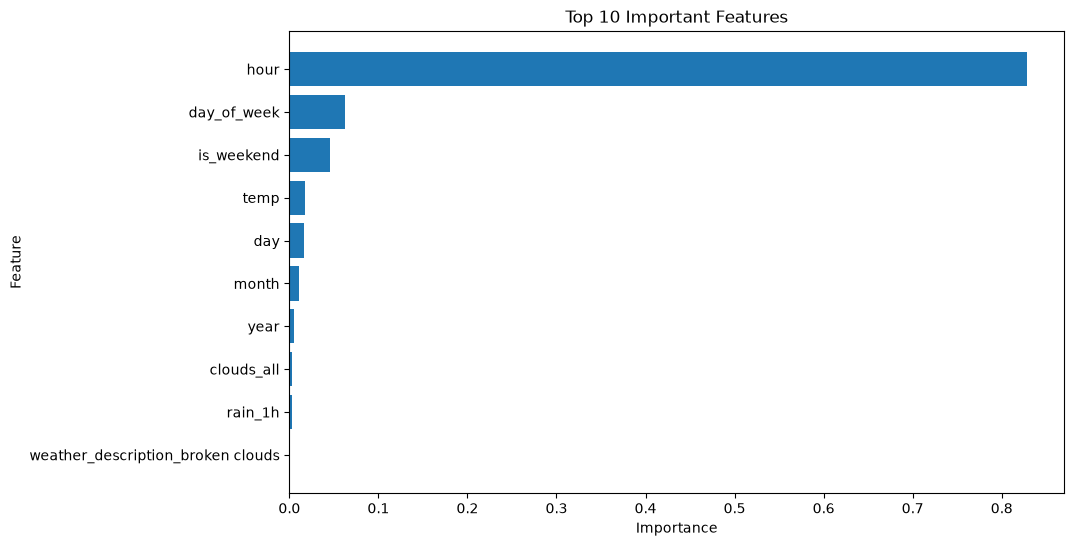

In [43]:
plt.figure(figsize=(10,6))

plt.barh(feature_importance["Feature"].head(10),feature_importance["Importance"].head(10))

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title("Top 10 Important Features")

plt.gca().invert_yaxis()

plt.show()

In [44]:
import joblib
joblib.dump(model_rf, "traffic_model.pkl")

['traffic_model.pkl']

In [45]:
joblib.dump(list(X.columns),"model_features.pkl")

['model_features.pkl']